# Ranked Observable Objects

This notebook queries the MPC confirmation page for observatory OASI (`Y28`) and ranks provisional candidates that meet the observing criteria. These records are unconfirmed and do not establish an object's final orbit or physical nature.


## Selection and Ranking Criteria

- The analysis uses today's UTC date and does not substitute another date if the MPC has no ephemerides for today.
- CIPO requires the object to remain above the configured altitude for at least the configured duration during astronomical night (Sun altitude at or below `-18` degrees).
- The ranking function keeps candidates with magnitude `V <= 18` and maximum altitude `> 10` degrees.
- Priority order: highest maximum altitude, brightest magnitude (lowest V), then longest visible duration. This is an operational ranking, not a scientific-value score or an observability guarantee.


In [14]:
import pandas as pd
import cipo

OBSERVATORY_CODE = "Y28"
OBJECT_PAGE = "PCCP"  # Set to "PCCP" to query the Possible Comet Confirmation Page.
MAX_MAGNITUDE = 18.0
MIN_ALTITUDE_DEGREES = 10
MINIMUM_DURATION_MINUTES = 30


In [15]:
ranked_objects = cipo.get_prioritized_observable_objects(
    obs_code=OBSERVATORY_CODE,
    obj_type=OBJECT_PAGE,
    magnitude_max=MAX_MAGNITUDE,
    altitude_min=MIN_ALTITUDE_DEGREES,
    duration_min=MINIMUM_DURATION_MINUTES,
)


Fetching ephemeris via Selenium for PCCP (obs: Y28)...


In [16]:
objects_to_display = ranked_objects.copy()
if not objects_to_display.empty:
    objects_to_display["Max_Alt_Time_UTC"] = pd.to_datetime(
        objects_to_display["Max_Alt_Time_UTC"], utc=True
    ).dt.strftime("%Y/%m/%d %H:%M UTC")
display(objects_to_display)


,Prioridade,Temp Desig,R.A.,Decl.,V,Visible_Minutes,Max_Alt,Max_Alt_Time_UTC,Window_Start_UTC,Window_End_UTC


## Object-specific altitude chart

Set OBJECT_NAME below to select a temporary designation. The next cell retrieves and displays the complete OASI ephemeris. The final cell plots the object altitude, Moon altitude, and astronomical-night interval.


In [11]:
OBJECT_NAME = ranked_objects.iloc[0]["Temp Desig"] if not ranked_objects.empty else ""
OBJECT_NAME = 'SWAN26Q'
OBJECT_NAME


'SWAN26Q'

In [12]:
object_ephemeris = cipo.get_object_ephemeris(
    object_name=OBJECT_NAME,
    obs_code=OBSERVATORY_CODE,
    obj_type=OBJECT_PAGE,
)
display(object_ephemeris)


Fetching ephemeris via Selenium for PCCP (obs: Y28)...


,Date,UT,R.A. (J2000),Decl,Elong,V,Object Alt,Sun Alt,Motion min,Motion PA
0,2026 10 30,07,11 22 33.0,-06 38 26,43.4,13.6,+25,-16,1.02,195.7
1,2026 10 30,08,11 22 31.9,-06 39 25,43.4,13.6,+40,-02,1.02,195.9
2,2026 10 30,09,11 22 30.7,-06 40 24,43.4,13.6,+55,+12,1.02,196.2
3,2026 10 30,10,11 22 29.6,-06 41 23,43.5,13.6,+70,+27,1.02,196.3
4,2026 10 30,11,11 22 28.4,-06 42 22,43.5,13.6,+84,+42,1.02,196.4
5,2026 10 30,12,11 22 27.2,-06 43 21,43.6,13.6,+80,+56,1.02,196.4
6,2026 10 30,13,11 22 26.1,-06 44 20,43.6,13.6,+66,+70,1.02,196.4
7,2026 10 30,14,11 22 24.9,-06 45 19,43.7,13.6,+51,+83,1.02,196.3
8,2026 10 30,15,11 22 23.8,-06 46 18,43.7,13.6,+36,+78,1.02,196.1
9,2026 10 30,16,11 22 22.6,-06 47 16,43.7,13.6,+21,+64,1.02,195.9


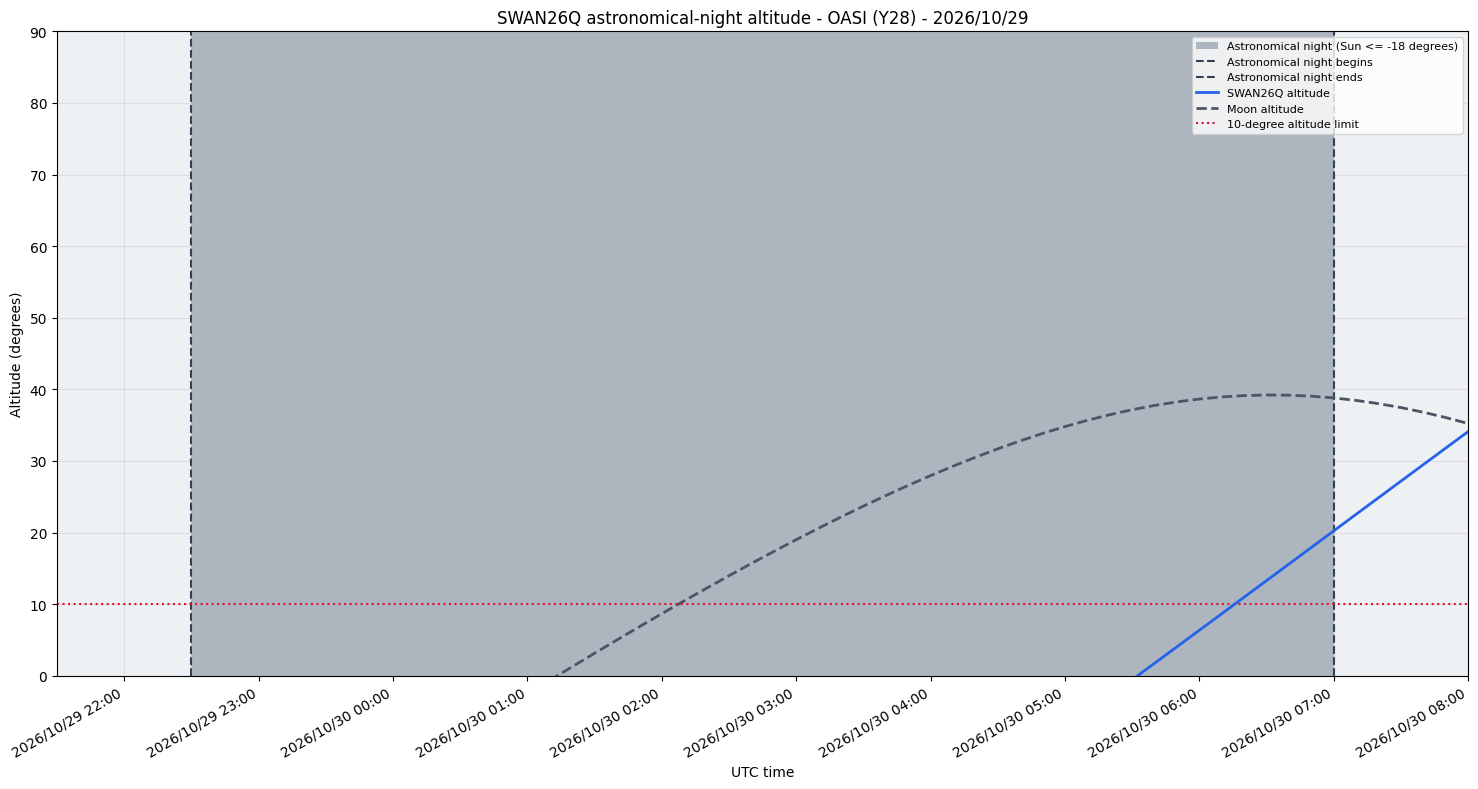

In [13]:
if OBJECT_NAME:
    cipo.plot_object_altitude(
        object_name=OBJECT_NAME,
        obs_code=OBSERVATORY_CODE,
        obj_type=OBJECT_PAGE,
        ephemeris_dataframe=object_ephemeris,
    )
